**Aim:** Differential Expression (DE) analysis comparing cells from different conditions (i.e. MDMA, Meth, Saline).
**Tools**
- `limma` – gene level 
- `iPAGE` – pathway level

# Differential analysis 

> Many methods have been used to determine differential gene expression from single-cell RNA (scRNA)-seq data. 

> Prefiltering of lowly expressed genes has important effects, particularly for some of the methods developed for bulk RNA-seq data analysis. However, we found that bulk RNA-seq analysis methods do not generally perform worse than those developed specifically for scRNA-seq. 

Source: [Soneson, C., Robinson, M. Bias, **robustness and scalability in single-cell differential expression analysis.** Nat Methods 15, 255–261 (2018).](https://doi.org/10.1038/nmeth.4612)

Also see 
[Wang, T., Li, B., Nelson, C.E. et al. **Comparative analysis of differential gene expression analysis tools for single-cell RNA sequencing data.** BMC Bioinformatics 20, 40 (2019).](https://doi.org/10.1186/s12859-019-2599-6)


[course chapter 12: Differential Expression (DE) analysis](https://biocellgen-public.svi.edu.au/mig_2019_scrnaseq-workshop/public/dechapter.html)


I'm also discussing this topic here https://github.com/abearab/sc-haircut-net/issues/3#issuecomment-832263091

> ### Estimate dispersion and DE using `DESeq2`
> Van den Berge and Perraudeau and others have shown the LRT may perform better for null hypothesis testing, so we use the LRT. In order to use the Wald test, it is recommended to set `useT=TRUE`.

> ### Plot dispersion estimates
> It is recommended to plot the dispersion estimates for DESeq2 on single-cell data. As discussed in the DESeq2 paper, it becomes difficult to accurately estimate the dispersion when the counts are very small, because the Poisson component of the variance is dominant. Therefore we see some very low dispersion estimates here, although the trend is still accurately capturing the upper proportion. So here everything looks good.


> If the parametric trend fails to fit (there would be a warning in this case), one should check the dispersion plot as above. If it looks like the dispersion fit is being thrown off by the low count genes with low dispersion estimates at the bottom of the plot, there is a relatively easy solution: one can filter out more of the low count genes only for the dispersion estimation step, so that the trend still captures the upper portion. This is pretty easy to do in DESeq2, to filter genes solely for the dispersion trend estimation, but to use a larger set for the rest of the analysis. An example of how this can be done:


In [1]:
import pandas as pd 
import scanpy as sc

In [2]:
def prep_diffexp_input(adata,name):
    counts = pd.DataFrame(
        adata.layers["counts"].T,
        columns = adata.obs.index.tolist(),
        index = adata.var.index.tolist()
    )

    meta = adata.obs[['batch','group']].copy()

    meta['treat'] = meta.batch.str.contains('acute').replace({True:'acute',False:'not-acute'})
    meta['rep'] = meta.batch.str[-1]

    counts.to_csv(f'diffexp/{name}_counts.txt',  sep='\t')
    meta.to_csv(f'diffexp/{name}_meta.txt',sep='\t')

In [4]:
ls celltyping/*h5ad.gz

celltyping/adata_neuron-clustered.h5ad.gz
celltyping/adata_non_neuron-clustered-labeled.h5ad.gz


In [5]:
results_file = 'celltyping/adata_neuron-clustered.h5ad.gz'

adata_neuron = sc.read_h5ad(results_file)

In [ ]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron = sc.read_h5ad(results_file)

In [8]:
set(adata_non_neuron.obs.label)

{'Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'}

## Prep inputs

In [6]:
prep_diffexp_input(adata_neuron,'all_neurons')

### Astrocytes

In [9]:
Astrocytes = adata_non_neuron[adata_non_neuron.obs.label == 'Astrocytes'].copy()

In [10]:
prep_diffexp_input(Astrocytes,'Astrocytes')

### Microglia

In [11]:
Microglia = adata_non_neuron[adata_non_neuron.obs.label == 'Microglia'].copy()

In [12]:
prep_diffexp_input(Microglia,'Microglia')

### Endothelial


In [13]:
Endothelial = adata_non_neuron[adata_non_neuron.obs.label == 'Endothelial'].copy()

In [14]:
prep_diffexp_input(Endothelial,'Endothelial')

### Oligodendrocytes

In [15]:
Oligodendrocytes = adata_non_neuron[adata_non_neuron.obs.label == 'Oligodendrocytes'].copy()

In [16]:
prep_diffexp_input(Oligodendrocytes,'Oligodendrocytes')

## Run DE

___

`deseq` env

In [3]:
!Rscript diffexp.R all_neurons

### Astrocytes

In [4]:
!Rscript diffexp.R Astrocytes

### Microglia

In [5]:
!Rscript diffexp.R Microglia

### Endothelial


In [6]:
!Rscript diffexp.R Endothelial

### Oligodendrocytes

In [2]:
!Rscript diffexp.R Oligodendrocytes

## Explore DE results

___

`deseq` R env

In [3]:
source('plots.R')

draw_volcano <- function(name,xlim=10,lfc.cutoff = 1, pval.cutoff = 0.05){
    read.table(paste0('diffexp/',name,'/delta_exp_MDMAvsSaline.txt')) %>% 
        plot_Volcano (x_min=-xlim,x_max=xlim,lfc.cutoff = lfc.cutoff, pval.cutoff = pval.cutoff ) +
        ggtitle(paste0(name,'\nMDMAvsSaline'))  -> p1

    read.table(paste0('diffexp/',name,'/delta_exp_MDMAvsMeth.txt')) %>% 
        plot_Volcano (x_min=-xlim,x_max=xlim,lfc.cutoff = lfc.cutoff, pval.cutoff = pval.cutoff ) +
        ggtitle('MDMAvsMeth')  -> p2

    read.table(paste0('diffexp/',name,'/delta_exp_MethvsSaline.txt')) %>% 
        plot_Volcano (x_min=-xlim,x_max=xlim,lfc.cutoff = lfc.cutoff, pval.cutoff = pval.cutoff ) +
        ggtitle('MethvsSaline')  -> p3

    return(p1 / p2/ p3)
}

In [ ]:
draw_volcano('all_neurons',xlim=5,lfc.cutoff=0.5)

### Astrocytes

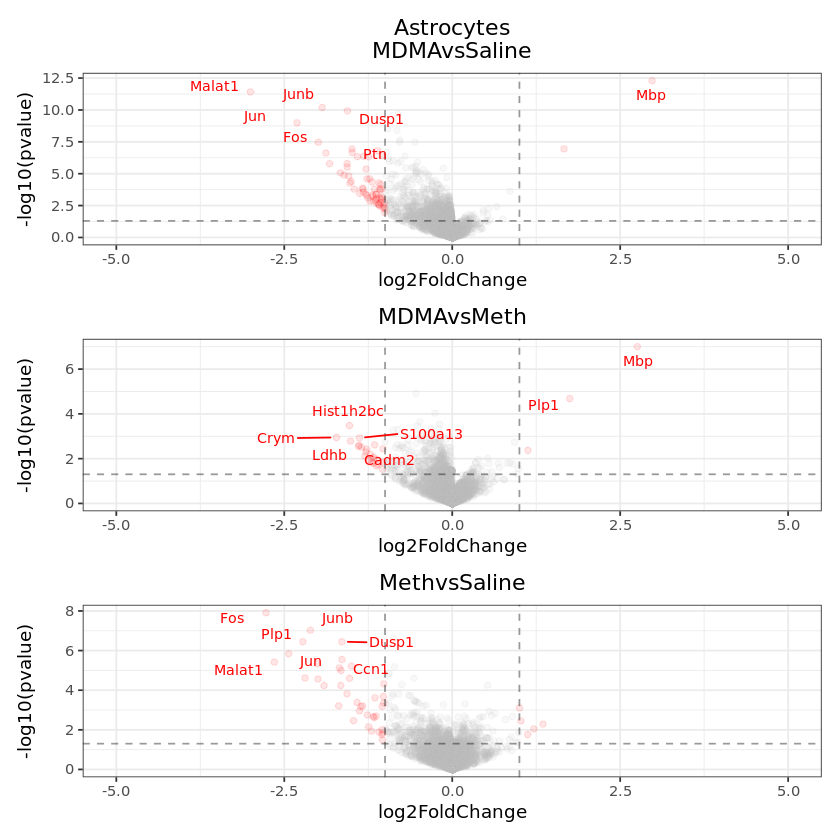

In [5]:
draw_volcano('Astrocytes',5)

### Microglia

Warning message:
“ggrepel: 3 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


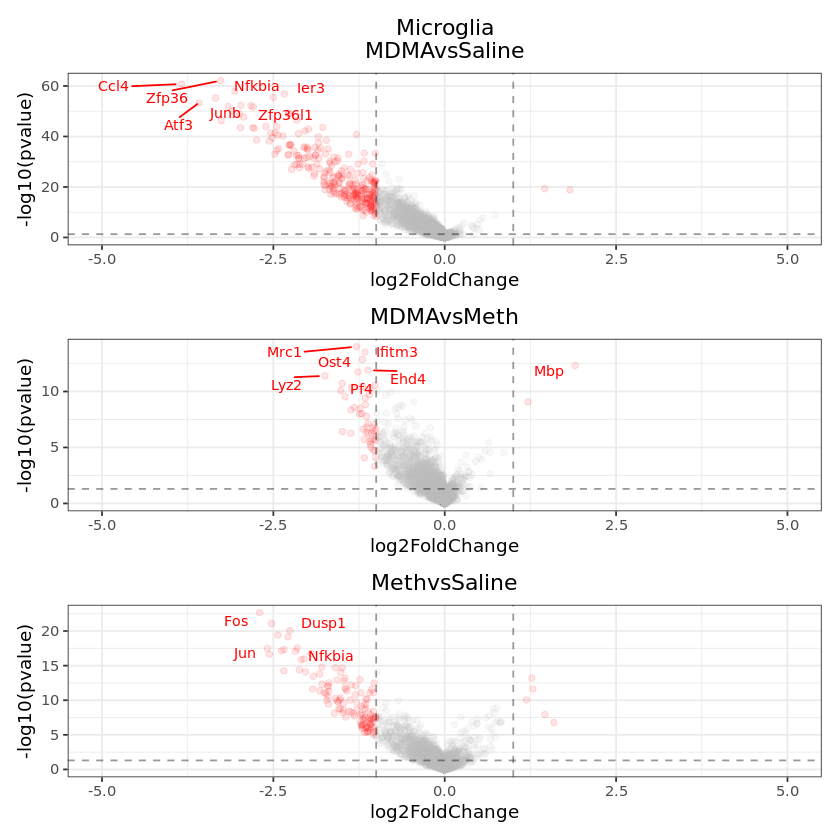

In [6]:
draw_volcano('Microglia',5)

### Endothelial


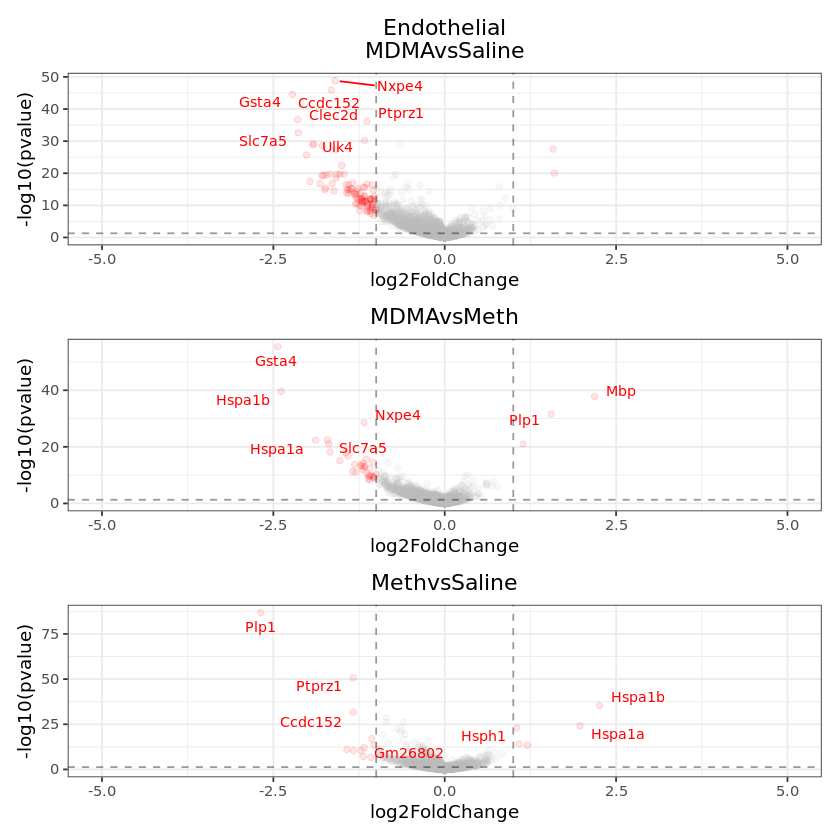

In [7]:
draw_volcano('Endothelial',5)

### Oligodendrocytes

Warning message:
“ggrepel: 4 unlabeled data points (too many overlaps). Consider increasing max.overlaps”
Warning message:
“ggrepel: 2 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


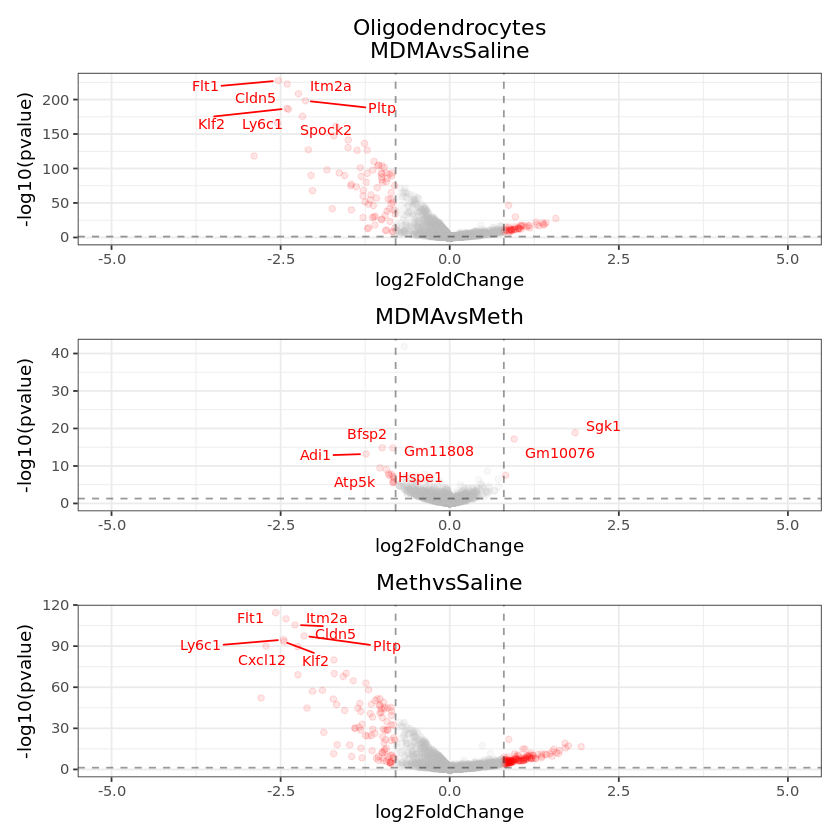

In [8]:
draw_volcano('Oligodendrocytes',xlim=5,lfc.cutoff=0.8)

# Pathway analysis

## GSEA

In [3]:
import pandas as pd 
from utils import *

from matplotlib import pyplot as plt
from venn import venn 

In [ ]:
import blitzgsea as blitz

In [4]:
def read_diffexp_table(name):
    d = {
        'MethvsSaline':pd.read_csv(
            f'diffexp/{name}/delta_exp_MethvsSaline.txt',  sep='\t'),
        'MDMAvsSaline':pd.read_csv(
            f'diffexp/{name}/delta_exp_MDMAvsSaline.txt',sep='\t'),
        'MDMAvsMeth':pd.read_csv(
            f'diffexp/{name}/delta_exp_MDMAvsMeth.txt',  sep='\t')
    }

    out = pd.concat(d.values(), axis=1, keys=d.keys())
    out.index = out.index.str.upper()
    return out

In [ ]:
m5_gmt = blitz.enrichr.read_gmt(
    '/data_gilbert/home/aarab/Projects/pager/annotations/mouse/m5.all.v2022.1.Mm.symbols.gmt'
)

In [ ]:
m8_gmt = blitz.enrichr.read_gmt(
    '/data_gilbert/home/aarab/Projects/pager/annotations/mouse/m8.all.v2022.1.Mm.symbols.gmt'
)

___

In [79]:
GSEA_res = {}

for cond in ['all_neurons',
             'Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes']:
    GSEA_res[cond] = {}
    for comp in ['MDMAvsMeth','MDMAvsSaline']:
        signature = read_diffexp_table(cond)[comp]['log2FoldChange'].reset_index()
        result = blitz.gsea(signature,m5_gmt,min_size=5,verbose=True)
        
        GSEA_res[cond][comp] = {
            'signature':signature,
            'result':result,
        }

Enrichment : 100%|██████████| 10652/10652 [00:13<00:00, 779.32it/s]


In [80]:
GSEA_res.keys()

dict_keys(['all_neurons', 'Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'])

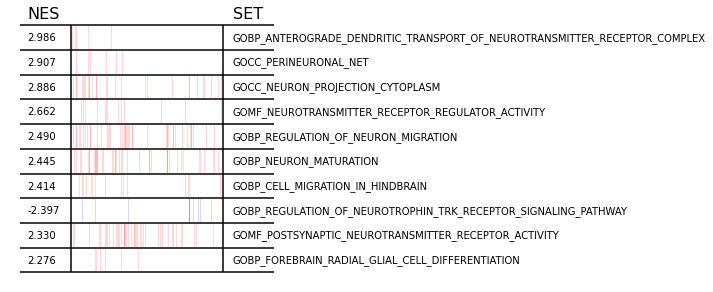

In [119]:
signature = GSEA_res['Oligodendrocytes']['MDMAvsMeth']['signature'].copy()
gsea_result = GSEA_res['Oligodendrocytes']['MDMAvsMeth']['result'].copy()

fig_table = blitz.plot.top_table(
    signature,m5_gmt,
    gsea_result[
        ((gsea_result.index.str.contains('NEURO')) | 
        (gsea_result.index.str.contains('BRAIN'))) & 
        (gsea_result.geneset_size < 50)
         ]
)
# fig_table.savefig("gsea_top_nes_pos_table.pdf", bbox_inches='tight')
fig_table

### 

In [ ]:
# %%bash
# zip -r diffexp/Astrocytes_DE.zip diffexp/Astrocytes_delta_exp_* 

# zip -r diffexp/Microglia_DE.zip diffexp/Microglia_delta_exp_* 

In [ ]:
for cond in ['all_neurons',
             'Astrocytes', 'Endothelial', 
             'Microglia', 'Oligodendrocytes'
            ]:
    
    writer = pd.ExcelWriter(f'diffexp/DEG_{cond}.xlsx', engine='xlsxwriter')
    read_diffexp_table(cond).to_excel(writer, sheet_name='comparisons')

    for comp in ['MDMAvsMeth','MDMAvsSaline']:
        GSEA_res[cond][comp]['result'].to_excel(writer, sheet_name=comp)
    writer.save()

# 

In [6]:
diffexp = {}

for cond in ['all_neurons',
             'Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes']:
    print(cond)
    diffexp[cond] = {}
    for comp in ['MethvsSaline','MDMAvsMeth','MDMAvsSaline']:
        print(comp)
        up,down = find_top(
            read_diffexp_table(cond)[comp],
            'log2FoldChange',0.1,'pvalue',0.05
        )
        diffexp[cond][f'{comp}_up'] = set(up.index)
        diffexp[cond][f'{comp}_down'] = set(down.index)
    print(20*'__')

all_neurons
MethvsSaline
up:  3685
down: 1837
MDMAvsMeth
up:  1426
down: 1249
MDMAvsSaline
up:  3648
down: 2113
________________________________________
Astrocytes
MethvsSaline
up:  143
down: 384
MDMAvsMeth
up:  33
down: 355
MDMAvsSaline
up:  31
down: 806
________________________________________
Endothelial
MethvsSaline
up:  354
down: 968
MDMAvsMeth
up:  182
down: 1189
MDMAvsSaline
up:  176
down: 1756
________________________________________
Microglia
MethvsSaline
up:  159
down: 1369
MDMAvsMeth
up:  77
down: 1321
MDMAvsSaline
up:  35
down: 2795
________________________________________
Oligodendrocytes
MethvsSaline
up:  965
down: 1157
MDMAvsMeth
up:  267
down: 582
MDMAvsSaline
up:  980
down: 1228
________________________________________


> - Meth & MDMA high and saline low
> - MDMA & saline high and Meth low


In [8]:
cmaps = ["cool", list("rgb"), "plasma", "viridis", "Set1"]

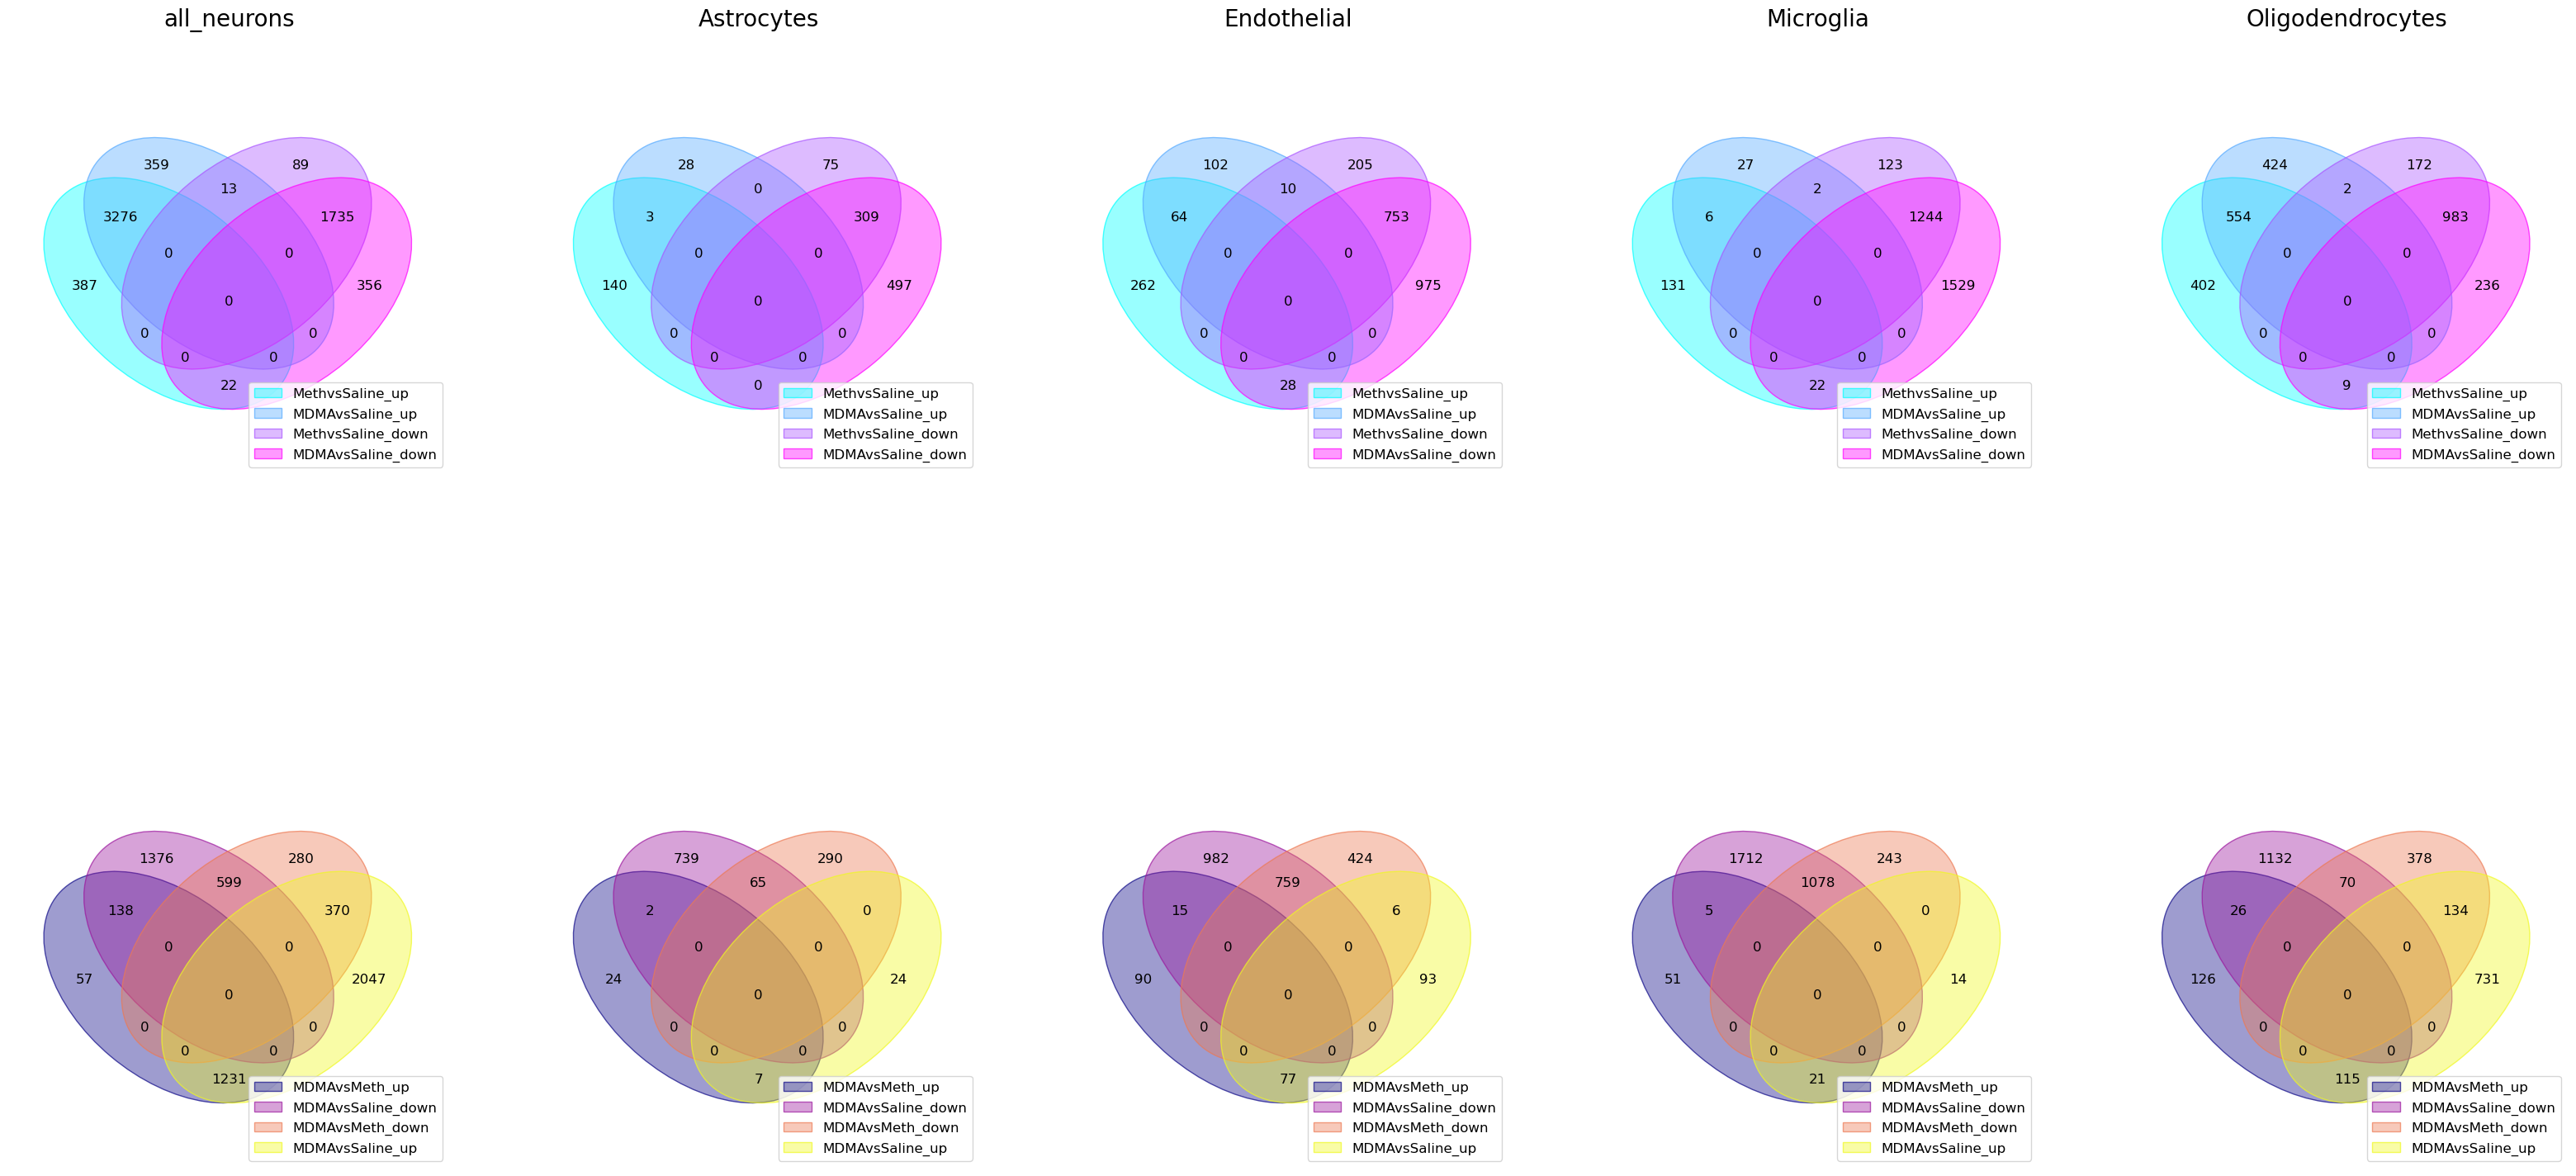

In [9]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(40, 20))

for cond,ax in zip(
    ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'],
    axes[0,[0,1,2,3,4]]):
    venn({comp: diffexp[cond][comp] for comp in ['MethvsSaline_up','MDMAvsSaline_up',
                                                'MethvsSaline_down','MDMAvsSaline_down']},
         ax=ax,legend_loc="lower right",fontsize=12,cmap=cmaps[0])
    ax.set_title(cond,fontsize=20)

for cond,ax in zip(
    ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'],
    axes[1,[0,1,2,3,4]]):
    venn({comp: diffexp[cond][comp] for comp in ['MDMAvsMeth_up','MDMAvsSaline_down',
                                                 'MDMAvsMeth_down','MDMAvsSaline_up'
                                                ]},
         ax=ax,legend_loc="lower right",fontsize=12,cmap=cmaps[2])
    # ax.set_title(cond,fontsize=20)
fig.savefig('diffexp/venn_full.pdf')
plt.show()

___
- generate similar diagram for MDMAvsMeth_up and SalinevsMeth_up
- look whether any of the 321 genes from the yellow circle in all_neurons overlap with any of the gens from the above analysis


___
We’re interested in genes which are higher in saline and lower in meth and the overlapping ones with MDMAvsMeth_up. 
However, you previously plotted MethvsSaline_up and overlapped it with MDMAvsMeth_up. If it is easier you could plot Meth vs Saline down as it should be similar to Saline vs Meth up. 


___
>@ Abe: do you think you can generate a list with MDMA vs Meth up overlapped with Saline vs Meth up? It may not be any different but perhaps there’ll be some other hits that may turn out to be interesting?


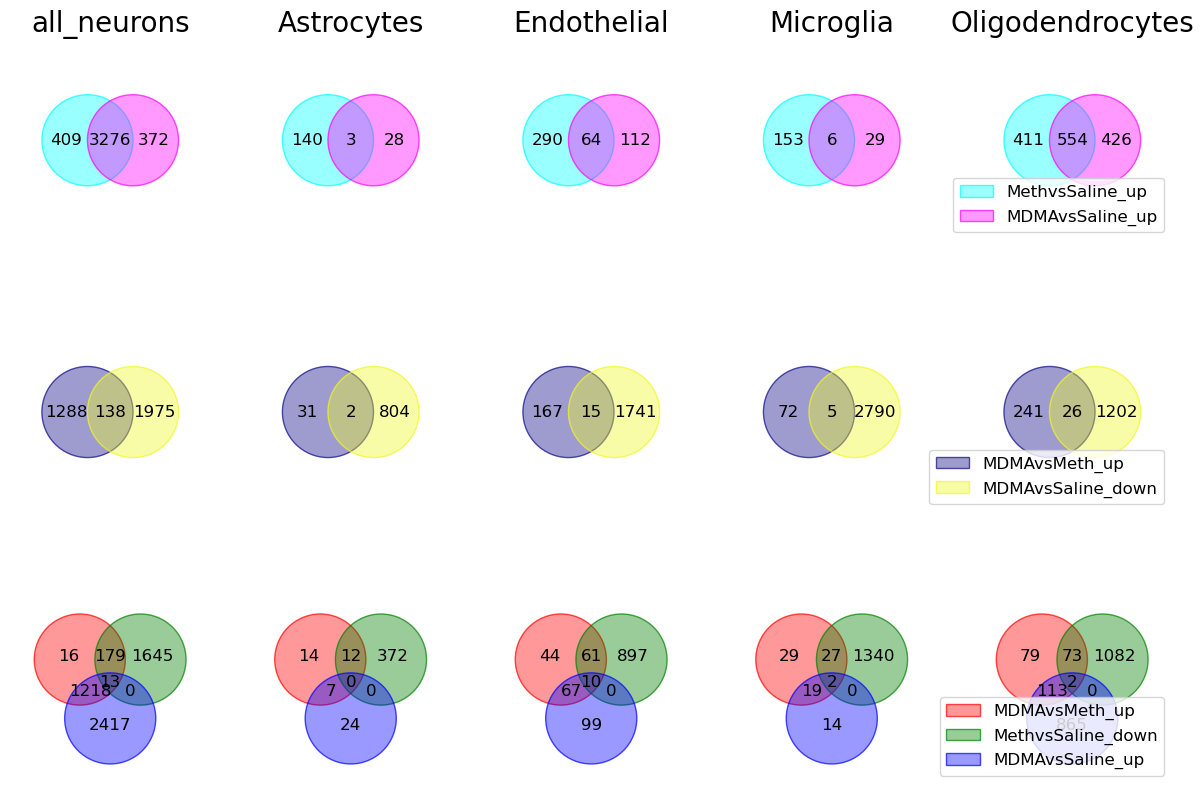

In [10]:
fig, axes = plt.subplots(ncols=5, nrows=3, figsize=(15, 10))

for cond,ax,l in zip(
    ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'],
    axes[0,[0,1,2,3,4]],[None,None,None,None,"lower right"]):
    venn({comp: diffexp[cond][comp] for comp in ['MethvsSaline_up','MDMAvsSaline_up']},
         ax=ax,legend_loc=l,fontsize=12,cmap=cmaps[0])
    ax.set_title(cond,fontsize=20)

for cond,ax,l in zip(
    ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'],
    axes[1,[0,1,2,3,4]],[None,None,None,None,"lower right"]):
    venn({comp: diffexp[cond][comp] for comp in ['MDMAvsMeth_up','MDMAvsSaline_down']},
         ax=ax,legend_loc=l,fontsize=12,cmap=cmaps[2])
    # ax.set_title(cond,fontsize=20)
    
for cond,ax,l in zip(
    ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'],
    axes[2,[0,1,2,3,4]],[None,None,None,None,"lower right"]):
    venn({comp: diffexp[cond][comp] for comp in ['MDMAvsMeth_up','MethvsSaline_down','MDMAvsSaline_up']},
         ax=ax,legend_loc=l,fontsize=12,cmap=cmaps[1])
    # ax.set_title(cond,fontsize=20)

fig.savefig('diffexp/venn.pdf')
plt.show()

In [19]:
with open('diffexp/venn-DEGs.txt', 'w') as f:
    for cond in ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes']:
        print(cond,file=f)
        a,b,c = [diffexp[cond][comp] for comp in ['MDMAvsMeth_up','MethvsSaline_down','MDMAvsSaline_up']]
        print(len(a - b - c),file=f)
        print(','.join(gene for gene in a - b - c),file=f)

        print(len((a & b) - c),file=f)
        print(','.join(gene for gene in (a & b) - c),file=f)

        print(len((a & c) - b),file=f)
        print(','.join(gene for gene in (a & c) - b),file=f)

        print(len((a & b & c)),file=f)
        print(','.join(gene for gene in (a & b & c)),file=f)

        print(file=f)
        print(file=f)

In [20]:
cat diffexp/venn-DEGs.txt

all_neurons
16
BARX2,DHCR24,TRP53INP2,SS18L2,HES6,HIPK3,CCNA2,H2AFX,SOX1,BYSL,TRABD,TTLL7,MTHFD2L,LHFPL2,YWHAH,POLE3
179
SEC11C,TUBB4A,ID1,CSPG5,NDUFA4,VCL,TNFRSF12A,RGCC,ANP32B,CARHSP1,SLC39A10,CTNNB1,JUN,GPCPD1,ATF4,HIST1H1C,SUMO2,ALAS1,FOSB,CCP110,UBE2C,GOLIM4,RASD1,DBNDD2,RHOB,PIM3,RPL22L1,FABP7,2410006H16RIK,DUSP3,REEP5,SMAD7,ERMN,CCND2,DBI,BSG,SYPL,SEPT10,MSMO1,RASL11A,PLS3,PLK2,CDK19,PICALM,MOBP,NEDD9,CFAP20,PRDX2,H2AFZ,MYH11,IER5L,CLTB,BNIP3L,CST3,BHLHE40,KLF4,KLHL2,PITPNA,BIRC5,TIPIN,TSC22D1,TUBB4B,EPHA4,PPP1R15A,BTG3,ZFAS1,MPZL1,GSTM5,SMDT1,TOP2A,LDHB,MAFF,SORT1,SPATA13,IER2,SERTAD1,GM20721,PTPRG,EID1,CAR2,PLLP,PSMC5,FABP5,INSIG1,NES,S100A1,PPP1CB,MAL,CENPB,NFKBIA,APLP1,AKAP12,TUBB5,CDC34,UBC,PDGFA,AP2A1,TJP1,CNP,MT3,KLF9,CPE,SOCS3,EGR1,TSPAN2,PNRC1,KLF2,ABCG2,CMTM5,MAG,FOS,CYSTM1,SNRPD1,SEPHS2,SNHG1,LY6C1,FDFT1,MTMR2,CCDC85B,NUDT4,OSTF1,NAMPT,ADAMTS1,COX5A,H1FX,PLN,GNA12,FOXJ1,GSTA4,PPP1R2,CTPS,PBK,HERPUD1,JUND,CPD,PCLAF,STMN1,JUNB,TSPAN5,COBLL1,PTGDS,CLDN5,MALAT1,GM10076,PO

In [14]:
print('MethvsSaline_up','MDMAvsSaline_up')
for cond in ['Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes']:
    print(cond)
    print(diffexp[cond]['MethvsSaline_up'] & diffexp[cond]['MDMAvsSaline_up'])
    print()
    print()

MethvsSaline_up MDMAvsSaline_up
Astrocytes
{'PFKM', 'FAM107A'}


Endothelial
{'LMNA', 'GM10076', 'EMP1', 'UBA52', 'MAFF', 'TNFRSF12A', 'PLAUR', 'ARID5A', 'CLIP1'}


Microglia
{'MOBP'}


Oligodendrocytes
{'PEA15A', 'ETV1', 'MOBP', 'SYS1', 'EPHB1', 'SPG20', 'USP31', 'PMP22', 'PTPN11', 'SH3KBP1', 'ENPP6', 'DIXDC1', 'CSRP1', 'IL33', 'GRM3', 'DPY19L1', 'PPP1R14A', 'PIM3', 'RNF141', 'DBNDD2', 'KLHL4', 'GSTM5', 'PRR18', 'ADO', 'TMEM229A', 'SEZ6L2', 'KCTD13', 'PLAAT3', 'CMTM5', 'TMCC3', 'ARHGAP23', 'CERK', 'TPPP3', 'USP54', 'KIF13B', 'INPP5F', 'SEC11C', 'LAP3', 'QDPR', 'GSTM7', 'MAST4', 'PDGFA', 'RCAN2', 'GPM6B', 'SLC5A3', 'NIPA1', 'ADAP1', 'PCSK1N', 'DAAM2', 'SLCO3A1', 'SLU7', 'STMN1', 'MBP', 'MYO1D', 'TNFAIP6', 'CDK19', 'MYRF', 'NDRG1', 'TRIM2', 'TRF', 'PACS2', 'KIF21A', 'SERPINB1A', 'MAPK8IP1', 'BCAS1', 'D7ERTD443E', 'SORT1', 'PRKACB', 'CYSTM1', 'CRYAB', 'TTYH2', 'EID1', 'SELENOM', 'SHTN1', 'DBI', 'FAM171B', 'STMN4', 'OTUD7B', 'SEPT8', 'PGP', 'CPD', 'APOD', 'ASPA', 'SPOCK3', 'GJB1', 'EVI2A'

## iPAGE

___
__logFC__
___

__FDR__

https://github.com/goodarzilab/server_wiki/tree/main/lab_softwares
> FDR is calculated as `sign(logFC)*(1-Pvalue)`.

In [1]:
import pandas as pd
import numpy as np 

from glob import glob 

def fdr_diff_table(file):
    df = pd.read_csv(file,sep='\t')
    df['fdr'] = np.sign(df.log2FoldChange ) * (1 - df.pvalue)
    df.index = df.index.str.upper()
    df[['fdr']].to_csv(file.replace('.txt','_fdr.txt'),sep='\t')
    df[['log2FoldChange','pvalue','fdr']].to_csv(file.replace('.txt','_log2fc.txt'),sep='\t')

In [ ]:
!rm -rv diffexp/*/*delta_exp*[log2fc,fdr].txt

In [ ]:
ls diffexp/*/delta_exp*.txt

In [ ]:
files = glob('diffexp/*/delta_exp*.txt')

for file in files:
    fdr_diff_table (file)


In [ ]:
!cat ~/Projects/pager/ipage_loop.sh | head -n 2

In [ ]:
%%bash 

export PAGEDIR='/data_gilbert/home/aarab/iPAGE'

for d in `ls -d diffexp/*/`; do 
    b=`basename $d`;
    echo $b
    cd $d;
    nohup ls *delta_exp*[log2fc,fdr].txt | parallel -j8 -k bash ~/Projects/pager/ipage_loop.sh {} &> /dev/null &
    cd ../../;
done

In [ ]:
!rm -rv diffexp/*/*delta_exp*[log2fc,fdr].txt

___

#

In [13]:
!date

Wed Aug 10 21:31:32 PDT 2022
